In [1]:

import torch
import os

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("No GPU detected. Enable a GPU runtime before training.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


Mount Google Drive

In [2]:

from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research"
EXPERIMENT_DIR = os.path.join(
    PROJECT_DIR, "Attention_UNet"
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

print("Experiment directory:", EXPERIMENT_DIR)
print("Directory exists:", os.path.isdir(EXPERIMENT_DIR))


Mounted at /content/drive
Experiment directory: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet
Directory exists: True


Downloading ans saving the repo


In [5]:

from google.colab import files
import os
import shutil
import zipfile

# Upload ZIP from your computer
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_names:
    raise ValueError("Please upload the repository ZIP file.")

zip_name = zip_names[0]

# Permanent Google Drive destination
BASE_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet"
ZIP_DEST = os.path.join(BASE_DIR, "attention_unet_original.zip")
SOURCE_DIR = os.path.join(BASE_DIR, "source_code")

os.makedirs(BASE_DIR, exist_ok=True)

# Save original ZIP to Drive
shutil.copy2(zip_name, ZIP_DEST)

# Verify and extract
with zipfile.ZipFile(ZIP_DEST, "r") as z:
    bad_file = z.testzip()
    if bad_file:
        raise ValueError(f"ZIP integrity check failed: {bad_file}")
    z.extractall("/content/attention_unet_extracted")

# Find the extracted repository folder
folders = [
    os.path.join("/content/attention_unet_extracted", name)
    for name in os.listdir("/content/attention_unet_extracted")
    if os.path.isdir(os.path.join("/content/attention_unet_extracted", name))
]

if not folders:
    raise RuntimeError("No repository folder found inside ZIP.")

if os.path.exists(SOURCE_DIR):
    shutil.rmtree(SOURCE_DIR)

shutil.copytree(folders[0], SOURCE_DIR)

print("ZIP saved:", ZIP_DEST)
print("Source code saved:", SOURCE_DIR)
print("\nRepository files:")

for root, dirs, filenames in os.walk(SOURCE_DIR):
    for filename in filenames:
        print(os.path.relpath(os.path.join(root, filename), SOURCE_DIR))


Saving Attention-U-Net-for-Lung-Segmentation-on-Chest-Xray-Scans-master.zip to Attention-U-Net-for-Lung-Segmentation-on-Chest-Xray-Scans-master.zip
ZIP saved: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/attention_unet_original.zip
Source code saved: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/source_code

Repository files:
utilities.py
lung_segmentation_sample.png
attention_unet.py
README.md
train.py
inference.py


Inspect the original model architecture

In [6]:

SOURCE_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/source_code"

# Display the original Attention U-Net architecture code
with open(f"{SOURCE_DIR}/attention_unet.py", "r") as f:
    print(f.read())




import torch
import torch.nn as nn
torch.cuda.empty_cache()


class up_conv(nn.Module):
    def __init__(self,ch_in,ch_out):
        super(up_conv,self).__init__()
        self.up = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(ch_in,ch_out,kernel_size=3,stride=1,padding=1,bias=True),
		    nn.BatchNorm2d(ch_out),
			nn.ReLU(inplace=True)
        )

    def forward(self,x):
        x = self.up(x)
        return x


class conv_block(nn.Module):
    def __init__(self,ch_in,ch_out):
        super(conv_block,self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(ch_in, ch_out, kernel_size=3,stride=1,padding=1,bias=True),
            nn.BatchNorm2d(ch_out),
            nn.ReLU(inplace=True),
            nn.Conv2d(ch_out, ch_out, kernel_size=3,stride=1,padding=1,bias=True),
            nn.BatchNorm2d(ch_out),
            nn.ReLU(inplace=True)
        )


    def forward(self,x):
        x = self.conv(x)
        return x

class Attention_bl

inspect the original training code

In [7]:

SOURCE_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/source_code"

for filename in ["README.md", "train.py", "utilities.py"]:
    path = f"{SOURCE_DIR}/{filename}"

    print(f"\n{'=' * 25} {filename} {'=' * 25}")

    with open(path, "r", encoding="utf-8") as f:
        print(f.read())



========================= README.md =========================

# Attention U-Net for Lung Segmentation on Chest Xray Scans

This repository contains code (training and inference) for Attention U-Net for the lung segmentation on Chest Xray scans.\
Train file:\
train.py \
Inference file:\
inference.py\
Helper functions:\
attention_unet.py\
utilities.py

# How to run in Google Colab (as you might want to bring into use the GPU capability)

1. Clone the repository into a Colab session
2. The data has to be located in the Google Drive in the exact same setting of diretories as mentioned in the code
3. Adjust the paths of directories containing dataset in your computer accordingly
4. Run the script train.py to train the best model
5. Find out the best model parameters using the validation loss column in the logs file
6. Run the script inference.py to load and run the exact same model

Note: You can run the repository in your local in the exact same manner as in Google Colab

![Caption: Lung

check your Montgomery dataset

In [8]:

import zipfile
from pathlib import Path

DATASET_ZIP = "/content/drive/MyDrive/NLM-MontgomeryCXRSet.zip"

assert Path(DATASET_ZIP).is_file(), (
    f"Dataset ZIP not found: {DATASET_ZIP}"
)

with zipfile.ZipFile(DATASET_ZIP, "r") as z:
    names = z.namelist()

    print("Total entries:", len(names))
    print("\nFirst 60 paths:")
    for name in names[:60]:
        print(name)

    image_files = [
        n for n in names
        if n.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
    ]

    print("\nImage-like files:", len(image_files))


Total entries: 573

First 60 paths:
MontgomerySet/
MontgomerySet/ClinicalReadings/
MontgomerySet/ClinicalReadings/MCUCXR_0001_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0002_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0003_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0004_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0005_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0006_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0008_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0011_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0013_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0015_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0016_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0017_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0019_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0020_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0021_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0022_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0023_0.txt
MontgomerySet/ClinicalReadings/MCUCXR_0024_0.txt
MontgomerySet/ClinicalReadings/MCUC

Verify X-rays and left/right masks

In [9]:

import zipfile
from collections import Counter

DATASET_ZIP = "/content/drive/MyDrive/NLM-MontgomeryCXRSet.zip"

with zipfile.ZipFile(DATASET_ZIP, "r") as z:
    names = z.namelist()

    # Identify files by their directory paths
    xray_files = [
        n for n in names
        if "/CXR_png/" in n and n.lower().endswith(".png")
    ]

    left_masks = [
        n for n in names
        if "/ManualMask/leftMask/" in n
        and n.lower().endswith((".png", ".gif", ".tif", ".tiff"))
    ]

    right_masks = [
        n for n in names
        if "/ManualMask/rightMask/" in n
        and n.lower().endswith((".png", ".gif", ".tif", ".tiff"))
    ]

    print("X-ray images:", len(xray_files))
    print("Left lung masks:", len(left_masks))
    print("Right lung masks:", len(right_masks))

    print("\nExample X-ray filenames:")
    for n in xray_files[:5]:
        print(n)

    print("\nExample left mask filenames:")
    for n in left_masks[:5]:
        print(n)

    print("\nExample right mask filenames:")
    for n in right_masks[:5]:
        print(n)


X-ray images: 138
Left lung masks: 138
Right lung masks: 138

Example X-ray filenames:
MontgomerySet/CXR_png/MCUCXR_0001_0.png
MontgomerySet/CXR_png/MCUCXR_0002_0.png
MontgomerySet/CXR_png/MCUCXR_0003_0.png
MontgomerySet/CXR_png/MCUCXR_0004_0.png
MontgomerySet/CXR_png/MCUCXR_0005_0.png

Example left mask filenames:
MontgomerySet/ManualMask/leftMask/MCUCXR_0001_0.png
MontgomerySet/ManualMask/leftMask/MCUCXR_0002_0.png
MontgomerySet/ManualMask/leftMask/MCUCXR_0003_0.png
MontgomerySet/ManualMask/leftMask/MCUCXR_0004_0.png
MontgomerySet/ManualMask/leftMask/MCUCXR_0005_0.png

Example right mask filenames:
MontgomerySet/ManualMask/rightMask/MCUCXR_0001_0.png
MontgomerySet/ManualMask/rightMask/MCUCXR_0002_0.png
MontgomerySet/ManualMask/rightMask/MCUCXR_0003_0.png
MontgomerySet/ManualMask/rightMask/MCUCXR_0004_0.png
MontgomerySet/ManualMask/rightMask/MCUCXR_0005_0.png


Verify filename matching

In [10]:
import zipfile
import os

DATASET_ZIP = "/content/drive/MyDrive/NLM-MontgomeryCXRSet.zip"

with zipfile.ZipFile(DATASET_ZIP, "r") as z:
    names = z.namelist()

    xray_ids = {
        os.path.splitext(os.path.basename(n))[0]
        for n in names
        if "/CXR_png/" in n and n.lower().endswith(".png")
    }

    left_ids = {
        os.path.splitext(os.path.basename(n))[0]
        for n in names
        if "/ManualMask/leftMask/" in n and n.lower().endswith(".png")
    }

    right_ids = {
        os.path.splitext(os.path.basename(n))[0]
        for n in names
        if "/ManualMask/rightMask/" in n and n.lower().endswith(".png")
    }

    print("X-ray images:", len(xray_ids))
    print("Left masks:", len(left_ids))
    print("Right masks:", len(right_ids))

    print("\nX-rays missing left masks:", sorted(xray_ids - left_ids))
    print("X-rays missing right masks:", sorted(xray_ids - right_ids))
    print("Left masks without X-rays:", sorted(left_ids - xray_ids))
    print("Right masks without X-rays:", sorted(right_ids - xray_ids))

    print("\nAll filenames matched:", xray_ids == left_ids == right_ids)

X-ray images: 138
Left masks: 138
Right masks: 138

X-rays missing left masks: []
X-rays missing right masks: []
Left masks without X-rays: []
Right masks without X-rays: []

All filenames matched: True


Extract the dataset

In [11]:
import os
import zipfile

DATASET_ZIP = "/content/drive/MyDrive/NLM-MontgomeryCXRSet.zip"
EXTRACT_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"

os.makedirs(os.path.dirname(EXTRACT_DIR), exist_ok=True)

if not os.path.exists(os.path.join(EXTRACT_DIR, "CXR_png")):
    with zipfile.ZipFile(DATASET_ZIP, "r") as z:
        z.extractall(os.path.dirname(EXTRACT_DIR))

    print("Dataset extracted successfully.")
else:
    print("Dataset appears to be already extracted.")

print("\nChecking folders:")
print("X-ray folder:", os.path.exists(os.path.join(EXTRACT_DIR, "CXR_png")))
print("Left-mask folder:", os.path.exists(os.path.join(EXTRACT_DIR, "ManualMask", "leftMask")))
print("Right-mask folder:", os.path.exists(os.path.join(EXTRACT_DIR, "ManualMask", "rightMask")))

Dataset extracted successfully.

Checking folders:
X-ray folder: True
Left-mask folder: True
Right-mask folder: True


Inspect image and mask dimensions

In [12]:
from PIL import Image
import numpy as np
import os

DATASET_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"

sample_name = "MCUCXR_0001_0.png"

xray_path = os.path.join(DATASET_DIR, "CXR_png", sample_name)
left_path = os.path.join(DATASET_DIR, "ManualMask", "leftMask", sample_name)
right_path = os.path.join(DATASET_DIR, "ManualMask", "rightMask", sample_name)

xray = np.array(Image.open(xray_path))
left_mask = np.array(Image.open(left_path))
right_mask = np.array(Image.open(right_path))

print("X-ray shape:", xray.shape)
print("X-ray mode:", Image.open(xray_path).mode)

print("\nLeft mask shape:", left_mask.shape)
print("Left mask pixel values:", np.unique(left_mask)[:20])

print("\nRight mask shape:", right_mask.shape)
print("Right mask pixel values:", np.unique(right_mask)[:20])

X-ray shape: (4020, 4892)
X-ray mode: L

Left mask shape: (4020, 4892)
Left mask pixel values: [False  True]

Right mask shape: (4020, 4892)
Right mask pixel values: [False  True]


Visualize the X-ray and masks

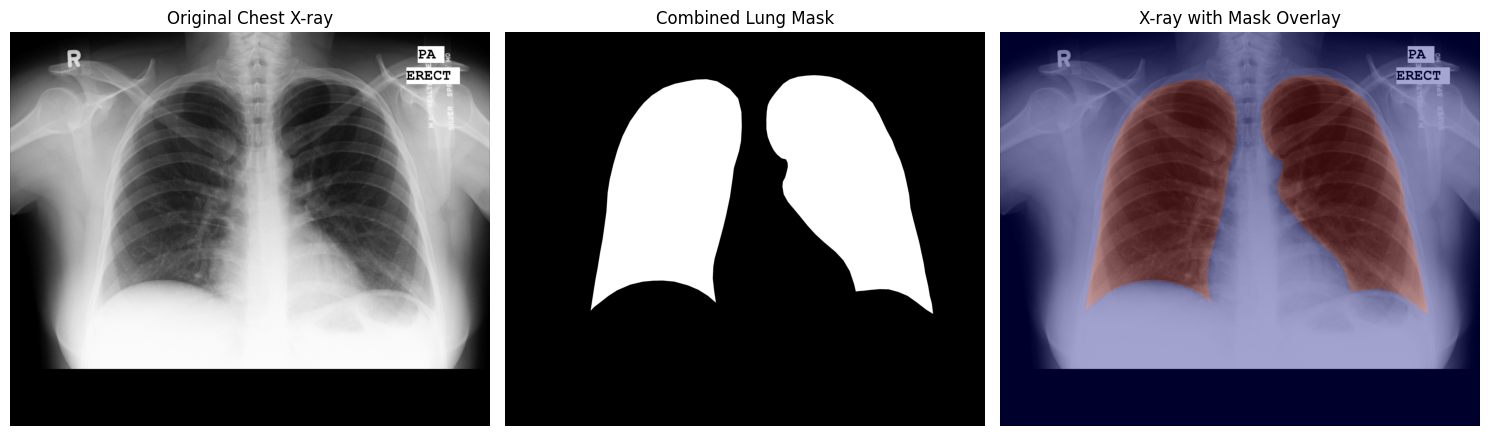

Combined mask shape: (4020, 4892)
Unique combined-mask values: [False  True]
Lung foreground pixels: 4753493


In [13]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os

DATASET_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
sample_name = "MCUCXR_0001_0.png"

xray = np.array(
    Image.open(os.path.join(DATASET_DIR, "CXR_png", sample_name))
)

left_mask = np.array(
    Image.open(os.path.join(DATASET_DIR, "ManualMask", "leftMask", sample_name))
).astype(bool)

right_mask = np.array(
    Image.open(os.path.join(DATASET_DIR, "ManualMask", "rightMask", sample_name))
).astype(bool)

combined_mask = np.logical_or(left_mask, right_mask)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(xray, cmap="gray")
axes[0].set_title("Original Chest X-ray")

axes[1].imshow(combined_mask, cmap="gray")
axes[1].set_title("Combined Lung Mask")

axes[2].imshow(xray, cmap="gray")
axes[2].imshow(combined_mask, cmap="jet", alpha=0.35)
axes[2].set_title("X-ray with Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Combined mask shape:", combined_mask.shape)
print("Unique combined-mask values:", np.unique(combined_mask))
print("Lung foreground pixels:", int(combined_mask.sum()))

Inspect the original Attention U-Net architecture

In [14]:
import os

MODEL_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/source_code"
)

model_file = os.path.join(MODEL_DIR, "attention_unet.py")

print("Model file exists:", os.path.exists(model_file))

with open(model_file, "r") as f:
    model_code = f.read()

print(model_code)

Model file exists: True


import torch
import torch.nn as nn
torch.cuda.empty_cache()


class up_conv(nn.Module):
    def __init__(self,ch_in,ch_out):
        super(up_conv,self).__init__()
        self.up = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(ch_in,ch_out,kernel_size=3,stride=1,padding=1,bias=True),
		    nn.BatchNorm2d(ch_out),
			nn.ReLU(inplace=True)
        )

    def forward(self,x):
        x = self.up(x)
        return x


class conv_block(nn.Module):
    def __init__(self,ch_in,ch_out):
        super(conv_block,self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(ch_in, ch_out, kernel_size=3,stride=1,padding=1,bias=True),
            nn.BatchNorm2d(ch_out),
            nn.ReLU(inplace=True),
            nn.Conv2d(ch_out, ch_out, kernel_size=3,stride=1,padding=1,bias=True),
            nn.BatchNorm2d(ch_out),
            nn.ReLU(inplace=True)
        )


    def forward(self,x):
        x = self.conv(x)
        retu

**Verify that the model runs**

Before deciding the next step, let's test the original model with a dummy tensor. This does not train the model or modify its architecture.

In [16]:
import sys
import torch

MODEL_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/source_code"
)

if MODEL_DIR not in sys.path:
    sys.path.insert(0, MODEL_DIR)

from attention_unet import AttU_Net

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AttU_Net(img_ch=3, output_ch=2).to(device)

# Small input for an initial architecture check
dummy_input = torch.randn(1, 3, 256, 256).to(device)

model.eval()
with torch.no_grad():
    output = model(dummy_input)

print("Device:", device)
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Device: cuda
Input shape: (1, 3, 256, 256)
Output shape: (1, 2, 256, 256)
Total parameters: 8744945
Trainable parameters: 8744945


Check the GPU and memory

In [17]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2),
        "GB"
    )

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


Check whether the dataset is already prepared

In [18]:
import os

DATASET_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "MontgomerySet"
)

folders = {
    "X-rays": os.path.join(DATASET_DIR, "CXR_png"),
    "Left masks": os.path.join(DATASET_DIR, "ManualMask", "leftMask"),
    "Right masks": os.path.join(DATASET_DIR, "ManualMask", "rightMask"),
}

for name, path in folders.items():
    print(f"{name}:")
    print("  Path:", path)
    print("  Exists:", os.path.isdir(path))
    if os.path.isdir(path):
        print("  File count:", len([
            f for f in os.listdir(path)
            if f.lower().endswith(".png")
        ]))
    print()

OUTPUT_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet"
)

print("Attention U-Net output directory:", OUTPUT_DIR)
print("Output directory exists:", os.path.isdir(OUTPUT_DIR))

X-rays:
  Path: /content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet/CXR_png
  Exists: True
  File count: 138

Left masks:
  Path: /content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet/ManualMask/leftMask
  Exists: True
  File count: 138

Right masks:
  Path: /content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet/ManualMask/rightMask
  Exists: True
  File count: 138

Attention U-Net output directory: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet
Output directory exists: True


Search for existing split files

In [19]:
import os

ROOT_DIR = "/content/drive/MyDrive/Lung_Segmentation_Research"

print("Searching for existing split or manifest files...\n")

matches = []

for root, dirs, files in os.walk(ROOT_DIR):
    # Skip large or irrelevant folders
    dirs[:] = [
        d for d in dirs
        if d not in {".git", "__pycache__", "node_modules"}
    ]

    for filename in files:
        lower_name = filename.lower()

        if any(term in lower_name for term in [
            "split", "manifest", "test_ids", "train_ids",
            "validation_ids", "val_ids", "dataset_config"
        ]):
            path = os.path.join(root, filename)
            matches.append(path)
            print(path)

if not matches:
    print("No matching split or manifest files found.")
else:
    print(f"\nFound {len(matches)} candidate file(s).")

Searching for existing split or manifest files...

No matching split or manifest files found.


Search for your existing notebooks

In [20]:
import os

SEARCH_ROOT = "/content/drive/MyDrive"

for root, dirs, files in os.walk(SEARCH_ROOT):
    dirs[:] = [
        d for d in dirs
        if d not in {".trash", ".ipynb_checkpoints", "__pycache__"}
    ]

    for filename in files:
        if filename.endswith(".ipynb") and any(
            term in filename.lower()
            for term in ["unet", "resunet", "lung", "segmentation"]
        ):
            print(os.path.join(root, filename))

/content/drive/MyDrive/Colab Notebooks/Unet.ipynb


In [21]:
import json

NOTEBOOK_PATH = "/content/drive/MyDrive/Colab Notebooks/Unet.ipynb"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "train_test_split",
    "random_split",
    "test_indices",
    "test_idx",
    "train_idx",
    "val_idx",
    "random_state",
    "seed",
    "split"
]

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(word in source.lower() for word in keywords):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(source[:6000])


==================== CELL 24 ====================
from torch.utils.data import random_split

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

==================== CELL 33 ====================
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from PIL import Image
from pathlib import Path

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, random_split

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)
print("GPU:", torch.cuda.get_device_name(0))

==================== CELL 39 ====================
# 80% training, 20% validation
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset,

Display the relevant notebook cells

In [22]:
import json

NOTEBOOK_PATH = "/content/drive/MyDrive/Colab Notebooks/Unet.ipynb"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i in range(48, min(60, len(notebook["cells"]))):
    cell = notebook["cells"][i]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 15} CELL {i} ({cell['cell_type']}) {'=' * 15}")
    print(source[:5000])


=============== CELL 48 (code) ===============
# Save the trained model weights
MODEL_PATH = "unet_lung_segmentation_epoch20.pth"

torch.save(model.state_dict(), MODEL_PATH)

print("Model saved successfully!")
print("Saved to:", MODEL_PATH)

=============== CELL 49 (code) ===============
def evaluate_each_image(model, dataset, device, threshold=0.5):
    model.eval()

    results = []

    with torch.no_grad():

        for i in range(len(dataset)):

            image, mask = dataset[i]

            # Add batch dimension
            image_input = image.unsqueeze(0).to(device)
            mask = mask.to(device)

            # Prediction
            logits = model(image_input)
            probabilities = torch.sigmoid(logits)

            prediction = (probabilities > threshold).float()

            # Remove batch dimension
            prediction = prediction.squeeze(0)

            # Flatten
            prediction_flat = prediction.view(-1)
            mask_flat = mask.view(-1)

      

Find how valid_images was defined

In [23]:
import json

NOTEBOOK_PATH = "/content/drive/MyDrive/Colab Notebooks/Unet.ipynb"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

terms = [
    "valid_images =",
    "LEFT_MASK_DIR",
    "RIGHT_MASK_DIR",
    "CXR_png",
    "glob("
]

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(term.lower() in source.lower() for term in terms):
        print(f"\n{'=' * 15} CELL {i} {'=' * 15}")
        print(source[:4000])


=============== CELL 10 ===============
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="Famatsu123/montgomery-shenzhen-tuberculosis-cxr",
    repo_type="dataset",
    local_dir="dataset",
    allow_patterns=[
        "MontgomerySet/CXR_png/*"
    ]
)

=============== CELL 13 ===============
from pathlib import Path

for folder in [
    "dataset/MontgomerySet/CXR_png",
    "dataset/MontgomerySet/ManualMask/leftMask",
    "dataset/MontgomerySet/ManualMask/rightMask"
]:
    files = list(Path(folder).iterdir())

    print("\n", folder)
    print("Total:", len(files))

    # Show files that are NOT PNG
    non_png = [f.name for f in files if f.suffix.lower() != ".png"]
    print("Non-PNG:", non_png)

=============== CELL 14 ===============
from PIL import Image
import matplotlib.pyplot as plt

image_path = "dataset/MontgomerySet/CXR_png/MCUCXR_0001_0.png"
left_path = "dataset/MontgomerySet/ManualMask/leftMask/MCUCXR_0001_0.png"
right_path = "dataset/Montgomer

Reproduce and save this notebook's split

In [24]:
from pathlib import Path
import numpy as np
import json
import os

DATASET_DIR = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

IMAGE_DIR = DATASET_DIR / "CXR_png"
LEFT_MASK_DIR = DATASET_DIR / "ManualMask" / "leftMask"
RIGHT_MASK_DIR = DATASET_DIR / "ManualMask" / "rightMask"

# Same sorted valid image list logic as the notebook
image_files = sorted(IMAGE_DIR.glob("*.png"))

valid_images = [
    img for img in image_files
    if (LEFT_MASK_DIR / img.name).exists()
    and (RIGHT_MASK_DIR / img.name).exists()
]

# Reproduce Cell 55
all_images = valid_images.copy()
rng = np.random.default_rng(42)
rng.shuffle(all_images)

total = len(all_images)
train_size = int(0.80 * total)
val_size = int(0.10 * total)

train_images = all_images[:train_size]
val_images = all_images[train_size:train_size + val_size]
test_images = all_images[train_size + val_size:]

print("Total valid images:", total)
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

split_manifest = {
    "seed": 42,
    "split_method": "numpy.default_rng(42) shuffle; 80/10/remaining",
    "dataset": "MontgomerySet",
    "train": [p.name for p in train_images],
    "validation": [p.name for p in val_images],
    "test": [p.name for p in test_images],
}

manifest_path = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/split_manifest.json"
)

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(split_manifest, f, indent=2)

print("\nManifest saved to:", manifest_path)
print("Unique IDs across splits:",
      len(set(split_manifest["train"] + split_manifest["validation"] + split_manifest["test"])))
print("Test filenames:")
print(split_manifest["test"])

Total valid images: 138
Train: 110
Validation: 13
Test: 15

Manifest saved to: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/split_manifest.json
Unique IDs across splits: 138
Test filenames:
['MCUCXR_0223_1.png', 'MCUCXR_0375_1.png', 'MCUCXR_0017_0.png', 'MCUCXR_0354_1.png', 'MCUCXR_0056_0.png', 'MCUCXR_0264_1.png', 'MCUCXR_0030_0.png', 'MCUCXR_0027_0.png', 'MCUCXR_0085_0.png', 'MCUCXR_0062_0.png', 'MCUCXR_0282_1.png', 'MCUCXR_0021_0.png', 'MCUCXR_0051_0.png', 'MCUCXR_0195_1.png', 'MCUCXR_0393_1.png']


Prepare the dataset for Attention U-Net

In [25]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import json

DATASET_DIR = Path(
    "/content/drive/MyDrive/Lung_Segmentation_Research/MontgomerySet"
)

MANIFEST_PATH = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/split_manifest.json"
)

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    split_manifest = json.load(f)

class MontgomeryLungDataset(Dataset):
    def __init__(self, filenames, augment=False, image_size=256):
        self.filenames = filenames
        self.augment = augment
        self.image_size = image_size

        self.image_dir = DATASET_DIR / "CXR_png"
        self.left_dir = DATASET_DIR / "ManualMask" / "leftMask"
        self.right_dir = DATASET_DIR / "ManualMask" / "rightMask"

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        image = Image.open(self.image_dir / filename).convert("RGB")
        left = np.array(Image.open(self.left_dir / filename)).astype(bool)
        right = np.array(Image.open(self.right_dir / filename)).astype(bool)

        combined = np.logical_or(left, right).astype(np.uint8) * 255
        mask = Image.fromarray(combined)

        # Resize image smoothly; preserve mask labels with nearest-neighbor.
        image = transforms.functional.resize(
            image, (self.image_size, self.image_size),
            interpolation=InterpolationMode.BILINEAR
        )
        mask = transforms.functional.resize(
            mask, (self.image_size, self.image_size),
            interpolation=InterpolationMode.NEAREST
        )

        # Apply synchronized geometric augmentation to training samples only.
        if self.augment:
            if np.random.random() < 0.5:
                image = transforms.functional.hflip(image)
                mask = transforms.functional.hflip(mask)

            angle = float(np.random.uniform(-5, 5))
            image = transforms.functional.rotate(
                image, angle, interpolation=InterpolationMode.BILINEAR
            )
            mask = transforms.functional.rotate(
                mask, angle, interpolation=InterpolationMode.NEAREST
            )

        image = transforms.functional.to_tensor(image)
        mask = torch.from_numpy(
            (np.array(mask) > 0).astype(np.int64)
        )

        return image, mask

train_dataset = MontgomeryLungDataset(
    split_manifest["train"], augment=True
)
val_dataset = MontgomeryLungDataset(
    split_manifest["validation"], augment=False
)
test_dataset = MontgomeryLungDataset(
    split_manifest["test"], augment=False
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

image, mask = train_dataset[0]

print("\nSample filename:", train_dataset.filenames[0])
print("Image tensor shape:", tuple(image.shape))
print("Image dtype:", image.dtype)
print("Mask tensor shape:", tuple(mask.shape))
print("Mask dtype:", mask.dtype)
print("Mask values:", torch.unique(mask).tolist())

Train samples: 110
Validation samples: 13
Test samples: 15

Sample filename: MCUCXR_0144_1.png
Image tensor shape: (3, 256, 256)
Image dtype: torch.float32
Mask tensor shape: (256, 256)
Mask dtype: torch.int64
Mask values: [0, 1]


Visualize one processed sample

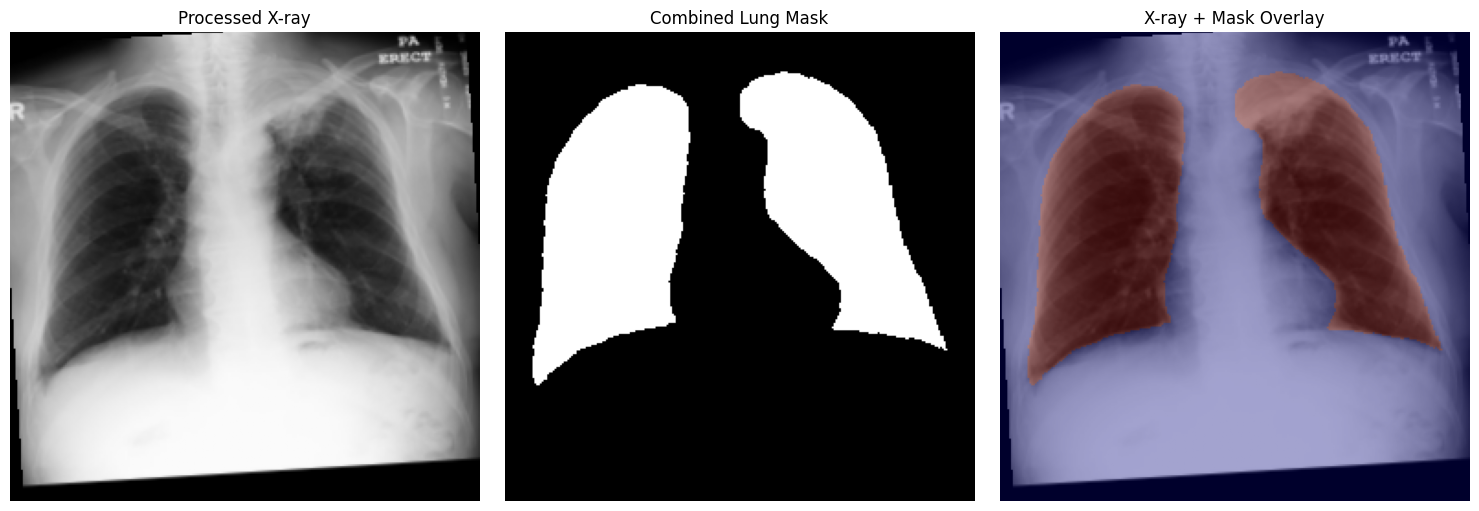

Filename: MCUCXR_0144_1.png
Image range: 0.0 to 0.9843137264251709
Mask foreground pixels: 18002


In [26]:
import matplotlib.pyplot as plt
import torch

image, mask = train_dataset[0]

image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_np)
axes[0].set_title("Processed X-ray")

axes[1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Combined Lung Mask")

axes[2].imshow(image_np)
axes[2].imshow(mask_np, cmap="jet", alpha=0.35, vmin=0, vmax=1)
axes[2].set_title("X-ray + Mask Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Filename:", train_dataset.filenames[0])
print("Image range:", float(image.min()), "to", float(image.max()))
print("Mask foreground pixels:", int(mask.sum()))

Batch and loss sanity check

In [27]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sys

MODEL_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/source_code"
)

if MODEL_DIR not in sys.path:
    sys.path.insert(0, MODEL_DIR)

from attention_unet import AttU_Net

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

images, masks = next(iter(train_loader))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AttU_Net(img_ch=3, output_ch=2).to(device)

images = images.to(device)
masks = masks.to(device)

criterion = nn.CrossEntropyLoss()

model.eval()
with torch.no_grad():
    logits = model(images)
    loss = criterion(logits, masks)

print("Device:", device)
print("Batch images:", tuple(images.shape))
print("Batch masks:", tuple(masks.shape))
print("Model output:", tuple(logits.shape))
print("Loss:", loss.item())
print("GPU memory allocated (MB):",
      round(torch.cuda.memory_allocated() / (1024**2), 2)
      if torch.cuda.is_available() else "N/A")

Device: cuda
Batch images: (2, 3, 256, 256)
Batch masks: (2, 256, 256)
Model output: (2, 2, 256, 256)
Loss: 0.6486149430274963
GPU memory allocated (MB): 39.09


**Set up the training configuration**

Our plan is to preserve the original file, create a separate corrected version, and verify the corrected model before training. We will not modify the original repository file.


**Step 1 — Back up the original model**

In [28]:
import os
import shutil
import hashlib

SOURCE_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/source_code"
)

original_file = os.path.join(SOURCE_DIR, "attention_unet.py")

backup_file = os.path.join(
    SOURCE_DIR, "attention_unet_original_backup.py"
)

corrected_file = os.path.join(
    SOURCE_DIR, "attention_unet_corrected.py"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            digest.update(chunk)
    return digest.hexdigest()

assert os.path.isfile(original_file), "Original model file not found."

original_hash = sha256_file(original_file)

# Create a backup without overwriting an existing backup.
if not os.path.exists(backup_file):
    shutil.copy2(original_file, backup_file)

# Create a separate working copy.
shutil.copy2(original_file, corrected_file)

print("Original file:", original_file)
print("Backup file:", backup_file)
print("Corrected working copy:", corrected_file)

print("\nOriginal SHA-256:", original_hash)
print("Backup matches original:", sha256_file(backup_file) == original_hash)
print("Original remains unchanged:", sha256_file(original_file) == original_hash)
print("Corrected copy initially matches original:",
      sha256_file(corrected_file) == original_hash)

Original file: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/source_code/attention_unet.py
Backup file: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/source_code/attention_unet_original_backup.py
Corrected working copy: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/source_code/attention_unet_corrected.py

Original SHA-256: 51bcb35e5030bca42492b5361960680306490a434cfa3dfa8a365bc7afe75809
Backup matches original: True
Original remains unchanged: True
Corrected copy initially matches original: True


**Step 2 — Inspect the decoder section**

In [29]:
with open(corrected_file, "r", encoding="utf-8") as f:
    code = f.read()

start = code.index("        x = self.Up6(x)")
end = code.index("        x = self.Conv_1x1(x)")

print(code[start:end])

        x = self.Up6(x)
        x5 = self.Att6(g=x,x=x5)
        x = torch.cat((x5, x),dim=1)
        x = self.Up_conv6(x)

        x = self.Up5(x)
        x5 = self.Att5(g=x,x=x4)
        x = torch.cat((x4, x),dim=1)
        x = self.Up_conv5(x)

        x = self.Up4(x)
        x3 = self.Att4(g=x,x=x3)
        x = torch.cat((x3, x),dim=1)
        x = self.Up_conv4(x)

        x = self.Up3(x)
        x2 = self.Att3(g=x,x=x2)
        x = torch.cat((x2,x),dim=1)
        x = self.Up_conv3(x)

        x = self.Up2(x)
        x1 = self.Att2(g=x,x=x1)
        x = torch.cat((x1, x),dim=1)
        x = self.Up_conv2(x)




**Step 3 — Correct the Att5 skip connection**

In [30]:
with open(corrected_file, "r", encoding="utf-8") as f:
    code = f.read()

old_line = "        x = torch.cat((x4, x),dim=1)"
new_line = "        x = torch.cat((x5, x),dim=1)"

count = code.count(old_line)

if count != 1:
    raise RuntimeError(
        f"Expected exactly one matching line, found {count}. "
        "No changes made."
    )

code = code.replace(old_line, new_line, 1)

with open(corrected_file, "w", encoding="utf-8") as f:
    f.write(code)

# Verify the correction
with open(corrected_file, "r", encoding="utf-8") as f:
    updated_code = f.read()

print("Att5 attention output used:", new_line in updated_code)
print("Original concatenation removed:", old_line not in updated_code)
print(
    "Original model remains unchanged:",
    sha256_file(original_file) == original_hash
)

start = updated_code.index("        x = self.Up5(x)")
end = updated_code.index("        x = self.Up4(x)")

print("\nCorrected Att5 section:\n")
print(updated_code[start:end])

Att5 attention output used: True
Original concatenation removed: True
Original model remains unchanged: True

Corrected Att5 section:

        x = self.Up5(x)
        x5 = self.Att5(g=x,x=x4)
        x = torch.cat((x5, x),dim=1)
        x = self.Up_conv5(x)




**Step 4 — Import and verify the corrected model**

In [31]:
import importlib.util
import torch

CORRECTED_FILE = corrected_file

spec = importlib.util.spec_from_file_location(
    "attention_unet_corrected",
    CORRECTED_FILE
)

corrected_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(corrected_module)

CorrectedAttU_Net = corrected_module.AttU_Net

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

corrected_model = CorrectedAttU_Net(
    img_ch=3,
    output_ch=2
).to(device)

# Test the model with a dummy input
dummy_input = torch.randn(1, 3, 256, 256, device=device)

corrected_model.eval()
with torch.no_grad():
    output = corrected_model(dummy_input)

print("Device:", device)
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))

print(
    "Corrected model parameters:",
    sum(p.numel() for p in corrected_model.parameters())
)

print(
    "Original model parameters:",
    sum(p.numel() for p in model.parameters())
)

print(
    "Parameter counts match:",
    sum(p.numel() for p in corrected_model.parameters())
    == sum(p.numel() for p in model.parameters())
)

print(
    "Output shape is correct:",
    tuple(output.shape) == (1, 2, 256, 256)
)

Device: cuda
Input shape: (1, 3, 256, 256)
Output shape: (1, 2, 256, 256)
Corrected model parameters: 8744945
Original model parameters: 8744945
Parameter counts match: True
Output shape is correct: True


**Step 5 — Configure training**

In [32]:
import os
import json
import torch
import torch.nn as nn

# Reuse the corrected model and existing datasets
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 2
EPOCHS = 20
LEARNING_RATE = 0.0002
IMAGE_SIZE = 256
SEED = 42

OUTPUT_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/corrected_experiment"
)

CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Reproducibility settings
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    corrected_model.parameters(),
    lr=LEARNING_RATE
)

config = {
    "model": "Corrected 2D Attention U-Net",
    "source_reference": (
        "https://github.com/aimalrehman92/"
        "Attention-U-Net-for-Lung-Segmentation-on-ChestXray-Scans"
    ),
    "modification": (
        "Att5 skip concatenation uses the attention-filtered "
        "features instead of the unfiltered encoder features."
    ),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "seed": SEED,
    "train_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "test_images": len(test_dataset),
    "device": str(device),
    "parameters": sum(p.numel() for p in corrected_model.parameters())
}

config_path = os.path.join(OUTPUT_DIR, "training_config.json")

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Training configuration saved:", config_path)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Device:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Training configuration saved: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/corrected_experiment/training_config.json
Checkpoint directory: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/corrected_experiment/checkpoints
Device: cuda
Training samples: 110
Validation samples: 13
Test samples: 15
Epochs: 20
Batch size: 2
Learning rate: 0.0002


**Step 6 — Training and validation loop**

In [33]:

import os
import csv
import json
import torch
from torch.utils.data import DataLoader

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Save paths
BEST_CHECKPOINT = os.path.join(CHECKPOINT_DIR, "best_attention_unet.pth")
LAST_CHECKPOINT = os.path.join(CHECKPOINT_DIR, "last_attention_unet.pth")
HISTORY_CSV = os.path.join(OUTPUT_DIR, "training_history.csv")

def calculate_dice_iou(logits, targets):
    # logits: [B, 2, H, W]; targets: [B, H, W]
    predictions = torch.argmax(logits, dim=1)
    dices, ious = [], []

    for i in range(targets.shape[0]):
        pred = predictions[i] == 1
        true = targets[i] == 1

        intersection = (pred & true).sum().float()
        pred_sum = pred.sum().float()
        true_sum = true.sum().float()
        union = pred_sum + true_sum - intersection

        dice = (2 * intersection + 1e-7) / (
            pred_sum + true_sum + 1e-7
        )
        iou = (intersection + 1e-7) / (union + 1e-7)

        dices.append(dice.item())
        ious.append(iou.item())

    return dices, ious


def evaluate_model(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_dice, all_iou = [], []

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, masks)

            total_loss += loss.item() * images.size(0)

            dice_values, iou_values = calculate_dice_iou(
                logits, masks
            )
            all_dice.extend(dice_values)
            all_iou.extend(iou_values)

    return (
        total_loss / len(loader.dataset),
        sum(all_dice) / len(all_dice),
        sum(all_iou) / len(all_iou)
    )


history = []
best_val_dice = -1.0

for epoch in range(1, EPOCHS + 1):
    corrected_model.train()
    running_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = corrected_model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    val_loss, val_dice, val_iou = evaluate_model(
        corrected_model, val_loader, criterion, device
    )

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_dice": val_dice,
        "val_iou": val_iou
    }
    history.append(record)

    # Save the most recent state after every epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict": corrected_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "config": config
    }, LAST_CHECKPOINT)

    # Save the best checkpoint based on validation Dice
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save({
            "epoch": epoch,
            "model_state_dict": corrected_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "history": history,
            "config": config,
            "best_val_dice": best_val_dice
        }, BEST_CHECKPOINT)

    # Persist history after every epoch
    with open(HISTORY_CSV, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=record.keys())
        writer.writeheader()
        writer.writerows(history)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_iou:.4f}"
    )

print("\nTraining complete.")
print("Best validation Dice:", round(best_val_dice, 4))
print("Best checkpoint:", BEST_CHECKPOINT)
print("Last checkpoint:", LAST_CHECKPOINT)
print("Training history:", HISTORY_CSV)


Epoch [01/20] | Train Loss: 0.4828 | Val Loss: 0.3838 | Val Dice: 0.8496 | Val IoU: 0.7427
Epoch [02/20] | Train Loss: 0.3156 | Val Loss: 0.2813 | Val Dice: 0.9436 | Val IoU: 0.8938
Epoch [03/20] | Train Loss: 0.2755 | Val Loss: 0.2534 | Val Dice: 0.9419 | Val IoU: 0.8914
Epoch [04/20] | Train Loss: 0.2417 | Val Loss: 0.2343 | Val Dice: 0.9515 | Val IoU: 0.9079
Epoch [05/20] | Train Loss: 0.2211 | Val Loss: 0.2898 | Val Dice: 0.8364 | Val IoU: 0.7302
Epoch [06/20] | Train Loss: 0.2026 | Val Loss: 0.1821 | Val Dice: 0.9642 | Val IoU: 0.9311
Epoch [07/20] | Train Loss: 0.1812 | Val Loss: 0.1675 | Val Dice: 0.9658 | Val IoU: 0.9341
Epoch [08/20] | Train Loss: 0.1641 | Val Loss: 0.1509 | Val Dice: 0.9681 | Val IoU: 0.9384
Epoch [09/20] | Train Loss: 0.1485 | Val Loss: 0.1478 | Val Dice: 0.9595 | Val IoU: 0.9225
Epoch [10/20] | Train Loss: 0.1356 | Val Loss: 0.1299 | Val Dice: 0.9701 | Val IoU: 0.9423
Epoch [11/20] | Train Loss: 0.1263 | Val Loss: 0.1219 | Val Dice: 0.9658 | Val IoU: 0.9342

Plot the training curves

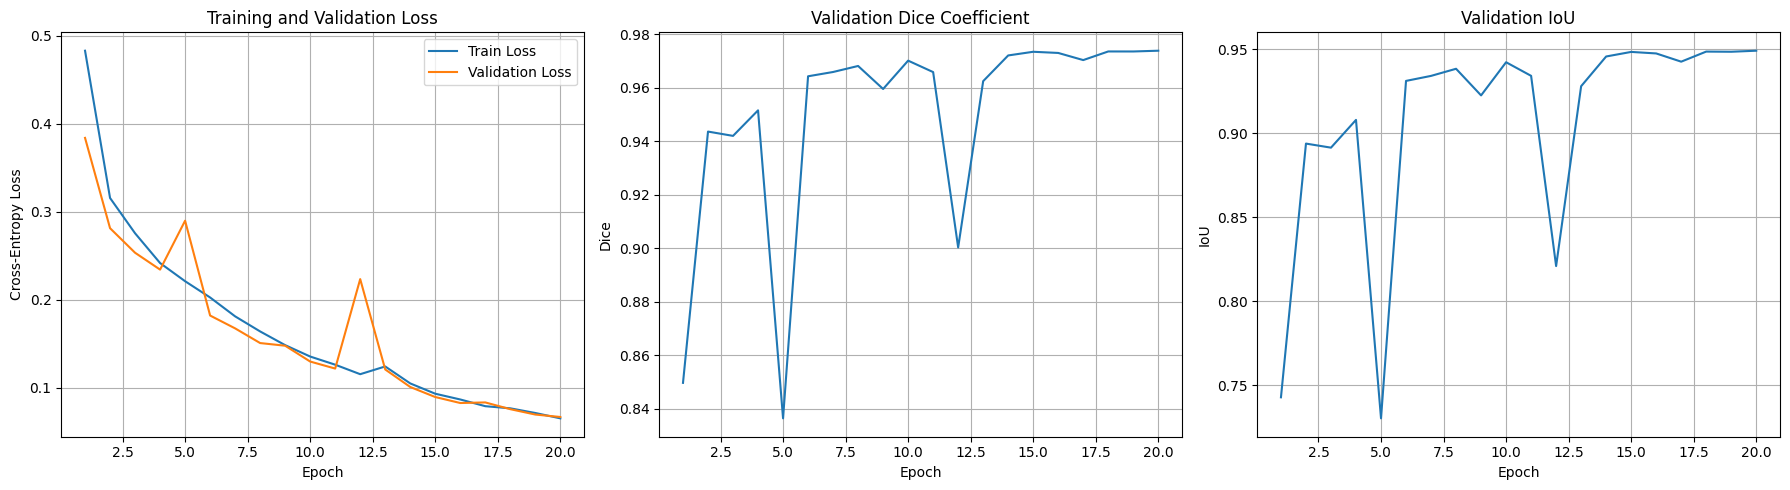

Best validation epoch:
epoch         20.000000
train_loss     0.065388
val_loss       0.066923
val_dice       0.973773
val_iou        0.949121


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import os

HISTORY_CSV = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/corrected_experiment/training_history.csv"
)

history_df = pd.read_csv(HISTORY_CSV)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_df["epoch"], history_df["val_dice"])
axes[1].set_title("Validation Dice Coefficient")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].grid(True)

axes[2].plot(history_df["epoch"], history_df["val_iou"])
axes[2].set_title("Validation IoU")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("IoU")
axes[2].grid(True)

plt.tight_layout()
plt.show()

print("Best validation epoch:")
print(history_df.loc[history_df["val_dice"].idxmax()].to_string())

Evaluate the best checkpoint on the test set

In [35]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

BEST_CHECKPOINT = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/corrected_experiment/checkpoints/"
    "best_attention_unet.pth"
)

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False
)

corrected_model.load_state_dict(checkpoint["model_state_dict"])
corrected_model.eval()

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

all_dice = []
all_iou = []
all_true = []
all_pred = []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = corrected_model(images)
        predictions = torch.argmax(logits, dim=1)

        pred = predictions[0] == 1
        true = masks[0] == 1

        intersection = (pred & true).sum().float()
        pred_sum = pred.sum().float()
        true_sum = true.sum().float()
        union = pred_sum + true_sum - intersection

        dice = (2 * intersection + 1e-7) / (
            pred_sum + true_sum + 1e-7
        )
        iou = (intersection + 1e-7) / (union + 1e-7)

        all_dice.append(dice.item())
        all_iou.append(iou.item())

        all_true.append(true.cpu().numpy().ravel())
        all_pred.append(pred.cpu().numpy().ravel())

y_true = np.concatenate(all_true).astype(np.uint8)
y_pred = np.concatenate(all_pred).astype(np.uint8)

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

precision = tp / (tp + fp + 1e-8)
recall = tp / (tp + fn + 1e-8)
f1 = 2 * precision * recall / (precision + recall + 1e-8)
accuracy = (tp + tn) / (tp + tn + fp + fn)

print("Checkpoint epoch:", checkpoint["epoch"])
print("\nTEST SET RESULTS")
print("-" * 35)
print(f"Mean Dice (per image): {np.mean(all_dice):.4f}")
print(f"Mean IoU (per image):  {np.mean(all_iou):.4f}")
print(f"Pixel Precision:       {precision:.4f}")
print(f"Pixel Recall:          {recall:.4f}")
print(f"Pixel F1-score:        {f1:.4f}")
print(f"Pixel Accuracy:        {accuracy:.4f}")
print(f"Test images evaluated: {len(test_dataset)}")

Checkpoint epoch: 20

TEST SET RESULTS
-----------------------------------
Mean Dice (per image): 0.9795
Mean IoU (per image):  0.9599
Pixel Precision:       0.9883
Pixel Recall:          0.9712
Pixel F1-score:        0.9797
Pixel Accuracy:        0.9895
Test images evaluated: 15


Visualize test predictions

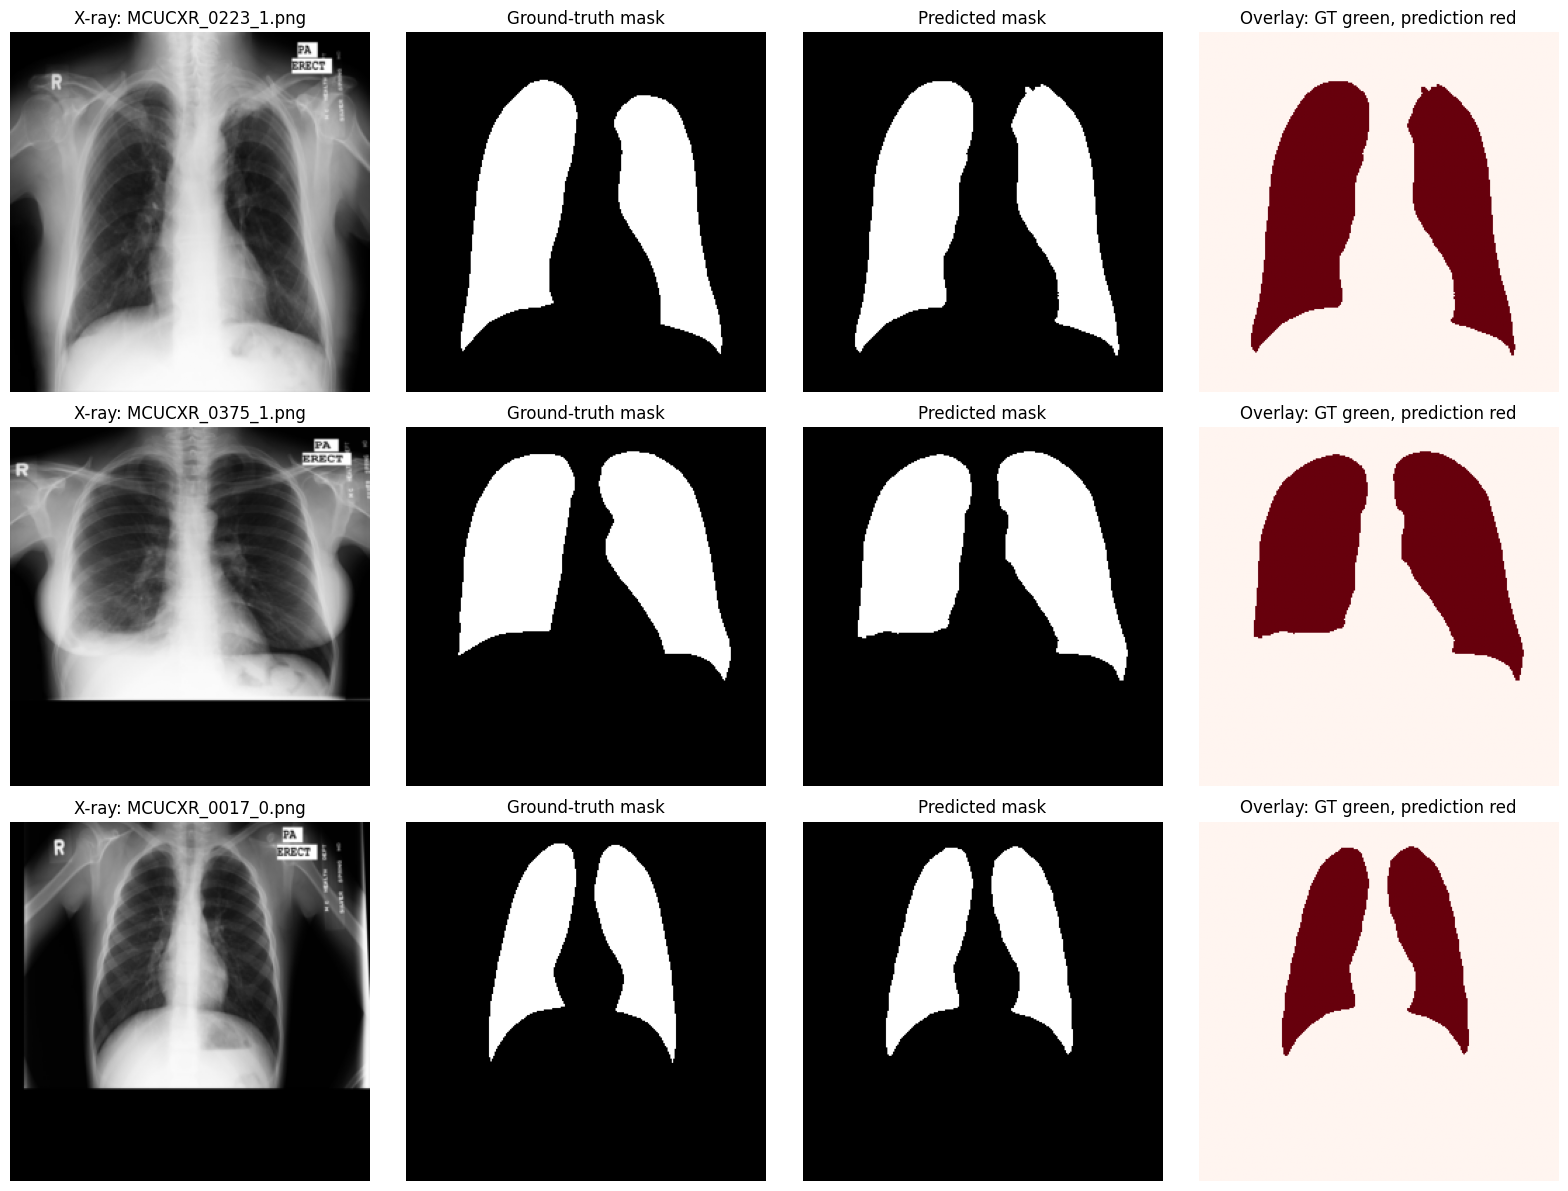

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

corrected_model.eval()

# Show the first three held-out test images
num_samples = min(3, len(test_dataset))

fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))

if num_samples == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(num_samples):
        image, mask = test_dataset[i]
        image_input = image.unsqueeze(0).to(device)

        logits = corrected_model(image_input)
        prediction = torch.argmax(logits, dim=1)[0].cpu().numpy()

        image_np = image.permute(1, 2, 0).cpu().numpy()
        mask_np = mask.cpu().numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title(f"X-ray: {test_dataset.filenames[i]}")

        axes[i, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Ground-truth mask")

        axes[i, 2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Predicted mask")

        axes[i, 3].imshow(image_np)
        axes[i, 3].imshow(mask_np, cmap="Greens", alpha=0.4)
        axes[i, 3].imshow(
            prediction,
            cmap="Reds",
            alpha=0.35 * prediction
        )
        axes[i, 3].set_title("Overlay: GT green, prediction red")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

Save the test results for your research paper

In [37]:
import os
import json
import pandas as pd
import numpy as np
import torch

OUTPUT_DIR = (
    "/content/drive/MyDrive/Lung_Segmentation_Research/"
    "Attention_UNet/corrected_experiment"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Per-image results from the held-out test set
per_image_df = pd.DataFrame({
    "filename": test_dataset.filenames,
    "dice": all_dice,
    "iou": all_iou
})

per_image_path = os.path.join(
    OUTPUT_DIR, "test_per_image_metrics.csv"
)
per_image_df.to_csv(per_image_path, index=False)

# Overall test metrics
test_metrics = {
    "model": "Corrected 2D Attention U-Net",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_images": len(test_dataset),
    "mean_dice_per_image": float(np.mean(all_dice)),
    "mean_iou_per_image": float(np.mean(all_iou)),
    "pixel_precision": float(precision),
    "pixel_recall": float(recall),
    "pixel_f1": float(f1),
    "pixel_accuracy": float(accuracy),
    "true_positive_pixels": int(tp),
    "true_negative_pixels": int(tn),
    "false_positive_pixels": int(fp),
    "false_negative_pixels": int(fn),
    "image_size": 256,
    "seed": 42
}

metrics_path = os.path.join(OUTPUT_DIR, "test_metrics.json")

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print("Saved overall metrics:", metrics_path)
print("Saved per-image metrics:", per_image_path)
print("\nPer-image results:")
print(per_image_df.to_string(index=False))

Saved overall metrics: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/corrected_experiment/test_metrics.json
Saved per-image metrics: /content/drive/MyDrive/Lung_Segmentation_Research/Attention_UNet/corrected_experiment/test_per_image_metrics.csv

Per-image results:
         filename     dice      iou
MCUCXR_0223_1.png 0.979114 0.959082
MCUCXR_0375_1.png 0.975725 0.952601
MCUCXR_0017_0.png 0.975698 0.952550
MCUCXR_0354_1.png 0.986012 0.972409
MCUCXR_0056_0.png 0.973424 0.948224
MCUCXR_0264_1.png 0.985047 0.970535
MCUCXR_0030_0.png 0.975108 0.951425
MCUCXR_0027_0.png 0.984125 0.968746
MCUCXR_0085_0.png 0.985334 0.971092
MCUCXR_0062_0.png 0.978366 0.957649
MCUCXR_0282_1.png 0.964410 0.931267
MCUCXR_0021_0.png 0.981257 0.963203
MCUCXR_0051_0.png 0.987068 0.974467
MCUCXR_0195_1.png 0.978356 0.957629
MCUCXR_0393_1.png 0.983860 0.968233
